# DATAImmo : une base SQL des ventes immobilières — corrigé de référence

**Projet OpenClassrooms — parcours Data Engineer — « Entraînez-vous avec SQL et créez votre BDD »**

> **Contexte.** Laplace Immo, réseau national d'agences immobilières, lance un POC : rassembler les ventes du
> **1er semestre 2020** (données DVF) dans une base relationnelle, conforme au RGPD, capable de répondre à
> **12 besoins** d'analyse exprimés en réunion (volumes de ventes, prix au m², classements).

| Partie | Ce qu'on y fait | Livrable |
|---|---|---|
| 1. Comprendre et modéliser | lire les 3 fichiers, repérer les pièges, dictionnaire, schéma 3NF | dictionnaire des données, schéma |
| 2. Créer et charger | construire les 4 tables, charger, **prouver** que rien n'est perdu | base SQLite |
| 3. Interroger | une requête par besoin, résultat, lecture en analyste | requêtes et résultats (présentation) |

L'apprenant fait ce travail avec un tableur et SQLite Studio ; le corrigé utilise Python pour que chaque étape
soit **reproductible et vérifiée**. Les requêtes, elles, sont du SQL pur (`sql/requetes/`), à copier-coller dans
SQLite Studio.

In [1]:
from pathlib import Path

import pandas as pd
from IPython.display import Image, Markdown, display

from dataimmo.db import DB_PATH, build_database, query
from dataimmo.dictionnaire import ENTREES, ecrire_dictionnaire
from dataimmo.io import PROJECT_DIR, load_sources
from dataimmo.schema_figure import dessiner

pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 160)
REQUETES = PROJECT_DIR / "sql" / "requetes"


def besoin(numero: int) -> pd.DataFrame:
    # Affiche le SQL du fichier sql/requetes/NN_*.sql, l'exécute sur la base et renvoie le résultat
    fichier = next(REQUETES.glob(f"{numero:02d}_*.sql"))
    sql = fichier.read_text(encoding="utf-8")
    display(Markdown(f"`{fichier.name}`\n```sql\n{sql}\n```"))
    return query(DB_PATH, sql)

---
## Partie 1 — Comprendre les données et modéliser

### 1.1 Trois fichiers, trois rôles

In [2]:
sources = load_sources()  # téléchargement vérifié par empreinte SHA-256, lecture en TEXTE (dtype=str)
dvf, population, referentiel = sources["dvf"], sources["population"], sources["referentiel"]
pd.DataFrame({
    "une ligne =": ["une vente d'un bien (DVF)", "une commune et sa population (INSEE)",
                    "une commune et son rattachement département / région"],
    "lignes": [len(dvf), len(population), len(referentiel)],
    "colonnes": [dvf.shape[1], population.shape[1], referentiel.shape[1]],
}, index=["Valeurs-foncières", "donnees_communes", "referentiel-geographique"])

,une ligne =,lignes,colonnes
Valeurs-foncières,une vente d'un bien (DVF),34169,46
donnees_communes,une commune et sa population (INSEE),34991,9
referentiel-geographique,une commune et son rattachement département / ...,38916,37


In [3]:
vides = dvf.columns[dvf.isna().all()]
print(f"{len(vides)} colonnes entièrement vides dans DVF :", list(vides))
dvf[["Date mutation", "Valeur fonciere", "Type local", "Code departement", "Code commune", "Code postal"]].head(3)

17 colonnes entièrement vides dans DVF : ['Code service CH', 'Reference document', '1 Articles CGI', '2 Articles CGI', '3 Articles CGI', '4 Articles CGI', '5 Articles CGI', 'No Volume', '2eme lot', 'Surface Carrez du 2eme lot', '3eme lot', 'Surface Carrez du 3eme lot', '4eme lot', 'Surface Carrez du 4eme lot', '5eme lot', 'Surface Carrez du 5eme lot', 'Identifiant local']


,Date mutation,Valeur fonciere,Type local,Code departement,Code commune,Code postal
0,2020-01-02 00:00:00,165000,Appartement,01,103,1170
1,2020-01-02 00:00:00,355680,Appartement,06,004,6160
2,2020-01-02 00:00:00,229500,Appartement,06,088,6000


### 1.2 Les pièges, démontrés un par un

**Piège 1 — les codes ne sont pas des nombres.** Si le tableur (ou pandas) lit les codes comme des nombres :

In [4]:
codes = pd.Series(["01", "2A", "06", "971"])
print("codes département :", codes.tolist())
print("convertis en nombres :", pd.to_numeric(codes, errors="coerce").tolist())
print("ventes en Corse (2A / 2B) :", dvf["Code departement"].isin(["2A", "2B"]).sum())
print("code postal tel que stocké dans le fichier :", dvf["Code postal"].iloc[0], "→ le zéro de 01170 est déjà perdu")

codes département : ['01', '2A', '06', '971']
convertis en nombres : [1.0, nan, 6.0, 971.0]
ventes en Corse (2A / 2B) : 251
code postal tel que stocké dans le fichier : 1170 → le zéro de 01170 est déjà perdu


Converti en nombre, « 01 » devient 1 (le zéro disparaît) et « 2A » devient une valeur manquante : dans une
colonne `INTEGER`, SQLite ne refuse rien mais mélange entiers et textes : les clés reconstruites ne
correspondent plus, et les 251 ventes de Corse disparaissent des jointures. Le fichier source a déjà subi
ce traitement sur le code postal (`1170` au lieu de `01170`), qu'il faut recomposer sur 5 caractères.
**Tous les codes sont du texte.**

**Piège 2 — le code postal n'identifie pas une commune.**

In [5]:
print("05100 →", sorted(dvf.loc[dvf["Code postal"] == "5100", "Commune"].unique()))
dvf["cle"] = dvf["Code departement"] + dvf["Code commune"]
codes_par_commune = dvf.groupby("cle")["Code postal"].nunique()
print(f"{(codes_par_commune > 1).sum()} communes ont plusieurs codes postaux ; Nice (06088) en a",
      codes_par_commune["06088"])

05100 → ['BRIANCON', 'MONTGENEVRE', 'NEVACHE']
57 communes ont plusieurs codes postaux ; Nice (06088) en a 4


Deux conséquences sur le modèle :
- la clé d'une commune est **code département + code commune** (`id_codedep_codecommune`), seule combinaison
  unique et présente dans les trois fichiers ;
- le code postal **décrit l'adresse du bien**, pas la commune : on le range dans `bien`. L'ébauche de schéma
  fournie le place dans `commune` ; c'est un choix possible si l'on accepte de ne garder qu'un code postal par
  commune, mais il perd de l'information pour 57 communes.

**Piège 3 — une donnée personnelle.**

In [6]:
print("Colonne nominative :", "Nom de l'acquereur" in dvf.columns,
      "—", dvf["Nom de l'acquereur"].nunique(), "noms différents")

Colonne nominative : True — 11112 noms différents


Le nom de l'acquéreur identifie une personne et ne sert à aucun des 12 besoins : on le **supprime**.
C'est de la **minimisation** (ne garder que les données nécessaires), pas une anonymisation : avec l'adresse, la
date et le prix, une vente reste rattachable à un bien et donc souvent à son propriétaire. Le pseudonymiser (le
remplacer par un identifiant) n'aurait d'intérêt que pour suivre un même acheteur dans le temps, ce que personne
ne demande.

**Piège 4 — l'encodage.**

In [7]:
abimes = referentiel["com_nom"][referentiel["com_nom"].str.contains("Ã|Å", na=False)]
print(len(abimes), "noms abîmés dans le référentiel, par exemple :", abimes.head(3).tolist())

281 noms abîmés dans le référentiel, par exemple : ['MoÃ«ns', 'Prévessin-MoÃ«ns', 'CaillouÃ«l-Crépigny']


Ces noms ont été enregistrés en UTF-8 puis relus comme du Windows-1252 : « œ » devient « Å“ ». La préparation
les répare (24 des 3 125 communes de la base sont concernées).

### 1.3 Le dictionnaire des données (livrable 1)

Une ligne par colonne de la base, avec les 7 informations attendues, plus la source :

In [8]:
dictionnaire = pd.DataFrame([e.__dict__ for e in ENTREES])
print("Écrit :", ecrire_dictionnaire().relative_to(PROJECT_DIR))
dictionnaire[["table", "code", "type", "longueur", "nature", "regle_gestion"]]

Écrit : livrables/dictionnaire_donnees.xlsx


,table,code,type,longueur,nature,regle_gestion
0,region,id_region,Texte,2,Élémentaire,"Clé primaire, unique, non nulle ; texte pour g..."
1,region,nom_region,Texte,50,Élémentaire,Non nul ; écrit comme dans la source (« Ile-de...
2,region,nom_regroupement,Texte,20,Élémentaire,Non nul ; 3 valeurs possibles
3,commune,id_codedep_codecommune,Texte,6,Concaténée,"Clé primaire, unique, non nulle"
4,commune,id_region,Texte,2,Élémentaire,Clé étrangère vers region.id_region ; non nulle
5,commune,code_departement,Texte,3,Élémentaire,"Non nul ; texte : « 2A », « 2B » (Corse), « 97..."
6,commune,code_commune,Texte,3,Élémentaire,Non nul ; toujours 3 caractères (« 004 »)
7,commune,nom_commune,Texte,50,Élémentaire,Non nul ; encodage réparé (« Schœlcher »)
8,commune,population,Entier,NC,Élémentaire,"Non nulle, positive ou nulle"
9,bien,id_bien,Entier,NC,Calculée,"Clé primaire, unique, non nulle"


### 1.4 Le schéma relationnel

La figure est générée à partir de `sql/schema.sql` : elle ne peut pas diverger de la base.

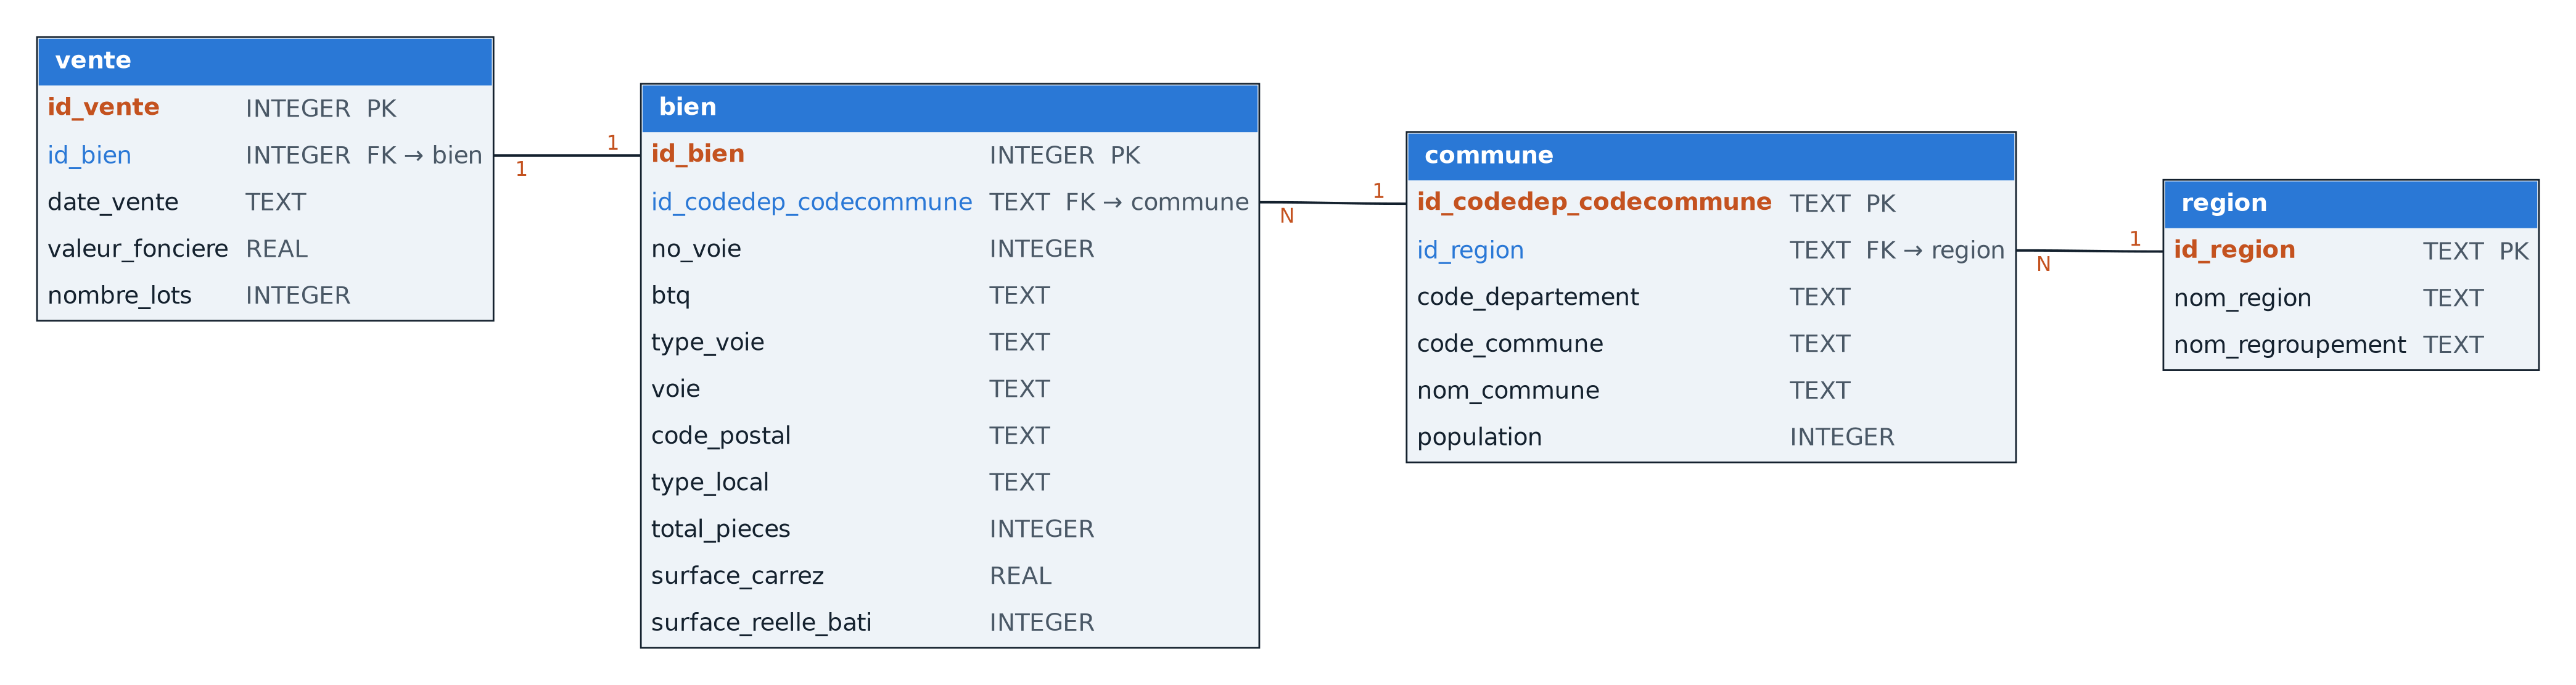

In [9]:
Image(filename=str(dessiner()), width=1000)

**Pourquoi ce schéma est en troisième forme normale (3NF)**
- **1NF** : chaque cellule contient une seule valeur atomique (l'adresse est découpée en numéro, indice, type de
  voie, voie, code postal).
- **2NF** : chaque table a une clé simple ; toutes les colonnes dépendent de toute la clé.
- **3NF** : aucune colonne ne dépend d'une autre colonne non-clé. Le nom de la région dépend du code région, pas de
  la commune : il vit donc dans `region`, une seule fois, au lieu d'être répété 3 125 fois.

---
## Partie 2 — Créer la base et prouver le chargement

`build_database()` crée les tables à partir de `sql/schema.sql`, prépare les 4 tables, écrit les 4 CSV et charge
la base avec les clés étrangères **activées**. Puis on vérifie.

In [10]:
controle = build_database()
controle

,table,lignes_csv,lignes_base
0,region,19,19
1,commune,3125,3125
2,bien,34169,34169
3,vente,34169,34169


**Preuve du chargement** : les mêmes vérifications, en SQL, telles qu'on les montrerait dans SQLite Studio.

In [11]:
query(DB_PATH, '''
    SELECT 'vente' AS table_, COUNT(*) AS lignes FROM vente
    UNION ALL SELECT 'bien', COUNT(*) FROM bien
    UNION ALL SELECT 'commune', COUNT(*) FROM commune
    UNION ALL SELECT 'region', COUNT(*) FROM region
''')

,table_,lignes
0,vente,34169
1,bien,34169
2,commune,3125
3,region,19


In [12]:
query(DB_PATH, '''
    SELECT
        (SELECT COUNT(*) FROM vente WHERE valeur_fonciere IS NULL) AS ventes_sans_valeur,
        (SELECT COUNT(*) FROM bien b LEFT JOIN commune c USING (id_codedep_codecommune)
          WHERE c.id_codedep_codecommune IS NULL)                  AS biens_sans_commune,
        (SELECT COUNT(*) FROM commune WHERE code_departement IN ('2A', '2B')) AS communes_corses
''')

,ventes_sans_valeur,biens_sans_commune,communes_corses
0,18,0,41


- 34 169 ventes et 34 169 biens : aucune ligne perdue, Corse comprise.
- 3 125 communes (celles qui ont au moins une vente) et 19 régions (référentiel complet).
- 18 ventes n'ont pas de valeur foncière : on les **garde** (elles comptent dans les volumes de ventes) avec une
  valeur `NULL`, que les moyennes ignorent. Une cellule vide importée comme texte vide (`''`) serait au contraire
  lue comme 0 par `AVG`.

**Les contraintes travaillent** : une vente rattachée à un bien qui n'existe pas est refusée.

In [13]:
import sqlite3

with sqlite3.connect(":memory:") as essai:
    essai.executescript((PROJECT_DIR / "sql" / "schema.sql").read_text(encoding="utf-8"))
    try:
        essai.execute("INSERT INTO vente VALUES (1, 999, '2020-01-02', 100000, 1)")
    except sqlite3.IntegrityError as erreur:
        print("Refusé par SQLite :", erreur)

Refusé par SQLite : FOREIGN KEY constraint failed


---
## Partie 3 — Répondre aux 12 besoins

Pour chaque besoin : la requête (fichier `sql/requetes/`), son résultat, et ce qu'un analyste en dit.
Le prix au m² d'une vente est `valeur foncière / surface Carrez`. Pour les besoins de prix au m², on donne la
**moyenne** (réponse attendue) **et la médiane** (calculée ici avec pandas, SQLite n'ayant pas de fonction
médiane) : quelques erreurs de saisie suffisent à tirer une moyenne.

On prépare une table « plate » (une ligne par vente) pour ces calculs de contrôle :

In [14]:
plate = query(DB_PATH, '''
    SELECT v.*, b.type_local, b.total_pieces, b.surface_carrez, b.surface_reelle_bati,
           c.id_codedep_codecommune, c.code_departement, c.nom_commune, c.population,
           r.id_region, r.nom_region
    FROM vente v
    JOIN bien b USING (id_bien)
    JOIN commune c USING (id_codedep_codecommune)
    JOIN region r USING (id_region)
''')
plate["prix_m2"] = plate["valeur_fonciere"] / plate["surface_carrez"]
plate["prix_m2"].describe().round(0)

count     34151.0
mean       4753.0
std        8570.0
min          44.0
25%        2202.0
50%        3377.0
75%        5640.0
max      989011.0
Name: prix_m2, dtype: float64

Médiane à environ 3 400 €/m², mais un maximum proche du million d'euros par m² : quelques ventes sont des
erreurs de saisie ou concernent une surface minuscule. C'est pourquoi la médiane accompagne chaque moyenne.

In [15]:
plate.nlargest(3, "prix_m2")[["nom_commune", "valeur_fonciere", "surface_carrez", "surface_reelle_bati", "prix_m2"]]

,nom_commune,valeur_fonciere,surface_carrez,surface_reelle_bati,prix_m2
30602,Paris 16e,9000000.0,9.10,10,989010.989011
21030,Paris 10e,336740.0,0.50,14,673480.000000
3624,Paris 7e,8577713.0,20.55,289,417406.958637


### Besoin 1 — Nombre d'appartements vendus au 1er semestre 2020

In [16]:
besoin(1)

`01_appartements_vendus.sql`
```sql
-- Besoin 1 — Nombre total d'appartements vendus au 1er semestre 2020.
-- Décortiquer : compter (COUNT) des ventes, filtrer le type de bien (Appartement) et la période (janv.-juin 2020).
-- Le type de bien est dans « bien », la date dans « vente » : une jointure est nécessaire.
SELECT
    COUNT(*) AS nb_appartements_vendus
FROM vente AS v
INNER JOIN bien AS b ON b.id_bien = v.id_bien
WHERE b.type_local = 'Appartement'
  AND v.date_vente BETWEEN '2020-01-01' AND '2020-06-30';

```

,nb_appartements_vendus
0,31378


**Lecture** : **31 378 appartements** vendus, soit 92 % des 34 169 ventes du fichier ; les 2 791 autres sont des maisons.
Ce poids des appartements est une caractéristique de l'extrait fourni pour le POC : il ne faut pas en déduire la
structure du marché français.

### Besoin 2 — Ventes d'appartements par région

In [17]:
besoin(2)

`02_ventes_appartements_par_region.sql`
```sql
-- Besoin 2 — Nombre de ventes d'appartements par région, 1er semestre 2020.
-- Décortiquer : compter des ventes (COUNT), par région (GROUP BY), appartements seulement (WHERE).
-- Chemin des jointures : vente -> bien -> commune -> region.
SELECT
    r.nom_region,
    COUNT(*) AS nb_ventes_appartements
FROM vente AS v
INNER JOIN bien    AS b ON b.id_bien = v.id_bien
INNER JOIN commune AS c ON c.id_codedep_codecommune = b.id_codedep_codecommune
INNER JOIN region  AS r ON r.id_region = c.id_region
WHERE b.type_local = 'Appartement'
  AND v.date_vente BETWEEN '2020-01-01' AND '2020-06-30'
GROUP BY r.id_region, r.nom_region
ORDER BY nb_ventes_appartements DESC;
-- 17 régions apparaissent : Mayotte et les collectivités d'outre-mer n'ont aucune vente dans le fichier.

```

,nom_region,nb_ventes_appartements
0,Ile-de-France,13995
1,Provence-Alpes-Côte d'Azur,3649
2,Auvergne-Rhône-Alpes,3253
3,Nouvelle-Aquitaine,1932
4,Occitanie,1640
5,Pays de la Loire,1357
6,Hauts-de-France,1254
7,Grand Est,984
8,Bretagne,983
9,Normandie,862


**Lecture** : Dans l'extrait, l'Île-de-France concentre **13 995 ventes, 45 % des appartements vendus**, loin devant
Provence-Alpes-Côte d'Azur (3 649) et Auvergne-Rhône-Alpes (3 253). 17 régions apparaissent : Mayotte et les
collectivités d'outre-mer sont dans la table `region` mais n'ont aucune vente.

### Besoin 3 — Proportion des ventes d'appartements par nombre de pièces

In [18]:
besoin(3)

`03_proportion_par_nombre_de_pieces.sql`
```sql
-- Besoin 3 — Proportion des ventes d'appartements par nombre de pièces.
-- Décortiquer : pour chaque nombre de pièces, (ventes de ce nombre de pièces) / (toutes les ventes d'appartements).
-- Le dénominateur est un total : on le calcule une fois dans une sous-requête.
-- Piège : COUNT(*) * 100 / total en entiers donne une division entière ; « 100.0 » force un résultat décimal.
SELECT
    b.total_pieces AS nb_pieces,
    COUNT(*) AS nb_ventes,
    ROUND(COUNT(*) * 100.0 / (
        SELECT COUNT(*)
        FROM vente AS v2
        INNER JOIN bien AS b2 ON b2.id_bien = v2.id_bien
        WHERE b2.type_local = 'Appartement'
    ), 2) AS proportion_pct
FROM vente AS v
INNER JOIN bien AS b ON b.id_bien = v.id_bien
WHERE b.type_local = 'Appartement'
GROUP BY b.total_pieces
ORDER BY b.total_pieces;
-- La modalité « 0 pièce » existe dans la source (30 appartements) : on la garde et on la signale.

```

,nb_pieces,nb_ventes,proportion_pct
0,0,30,0.10
1,1,6739,21.48
2,2,9783,31.18
3,3,8966,28.57
4,4,4460,14.21
5,5,1114,3.55
6,6,204,0.65
7,7,54,0.17
8,8,17,0.05
9,9,8,0.03


**Lecture** : Les **2 pièces (31,2 %) et 3 pièces (28,6 %)** dominent ; avec les 1 pièce (studios, 21,5 %), 81 % des ventes
portent sur des logements de 1 à 3 pièces. Les 5 pièces et plus ne pèsent que 4,5 %. La modalité « 0 pièce »
(30 ventes) vient de la source : à signaler plutôt qu'à corriger.

### Besoin 4 — Les 10 départements où le m² est le plus cher

In [19]:
besoin(4)

`04_top10_departements_prix_m2.sql`
```sql
-- Besoin 4 — Les 10 départements où le prix du mètre carré est le plus élevé.
-- Décortiquer : prix au m² d'une vente = valeur foncière / surface Carrez ; moyenne par département ; 10 premiers.
-- Les ventes sans valeur foncière (NULL) sont ignorées par AVG ; on affiche n pour juger la solidité de chaque moyenne.
SELECT
    c.code_departement,
    ROUND(AVG(v.valeur_fonciere / b.surface_carrez), 0) AS prix_m2_moyen,
    COUNT(*) AS nb_ventes
FROM vente AS v
INNER JOIN bien    AS b ON b.id_bien = v.id_bien
INNER JOIN commune AS c ON c.id_codedep_codecommune = b.id_codedep_codecommune
WHERE v.valeur_fonciere IS NOT NULL
GROUP BY c.code_departement
ORDER BY AVG(v.valeur_fonciere / b.surface_carrez) DESC   -- trier sur la valeur exacte, pas sur l'arrondi
LIMIT 10;

```

,code_departement,prix_m2_moyen,nb_ventes
0,75,12053.0,4840
1,92,7219.0,1813
2,94,5343.0,1926
3,06,4700.0,1343
4,74,4667.0,364
5,93,4345.0,1074
6,78,4225.0,1586
7,69,4059.0,1412
8,2A,4027.0,245
9,33,3764.0,1239


In [20]:
mediane_dep = plate.groupby("code_departement")["prix_m2"].agg(["median", "count"]).round(0)
mediane_dep.sort_values("median", ascending=False).head(10)  # variante : top 10 par médiane

,median,count
code_departement,,
75,11094.0,4840
92,6946.0,1813
94,4889.0,1926
06,4226.0,1343
69,3875.0,1412
93,3847.0,1074
78,3797.0,1586
74,3709.0,364
17,3700.0,105


**Lecture** : Paris est hors norme : **12 053 €/m²** en moyenne, 1,7 fois les Hauts-de-Seine (7 219). Le top 10 réunit la petite
couronne (92, 94, 93), les Yvelines, la Côte d'Azur (06), la Haute-Savoie (74), le Rhône (69), la Corse-du-Sud
(2A) et la Gironde (33). Avec la médiane, 9 départements sur 10 restent : la Gironde sort, la Charente-Maritime
(17) entre. Le haut du classement est solide, la 10ᵉ place ne l'est pas.

### Besoin 5 — Prix moyen du m² d'une maison en Île-de-France

In [21]:
besoin(5)

`05_prix_m2_maison_ile_de_france.sql`
```sql
-- Besoin 5 — Prix moyen du mètre carré d'une maison en Île-de-France.
-- Décortiquer : maisons seulement, région Île-de-France, moyenne des prix au m².
-- Piège : le référentiel écrit « Ile-de-France » sans accent ; on filtre sur le code région ('11'), plus sûr qu'un nom.
SELECT
    ROUND(AVG(v.valeur_fonciere / b.surface_carrez), 0) AS prix_m2_moyen_maison_idf,
    COUNT(*) AS nb_maisons
FROM vente AS v
INNER JOIN bien    AS b ON b.id_bien = v.id_bien
INNER JOIN commune AS c ON c.id_codedep_codecommune = b.id_codedep_codecommune
WHERE b.type_local = 'Maison'
  AND c.id_region = '11'
  AND v.valeur_fonciere IS NOT NULL;

```

,prix_m2_moyen_maison_idf,nb_maisons
0,3745.0,1059


In [22]:
maisons_idf = plate[(plate["type_local"] == "Maison") & (plate["id_region"] == "11")]
print(f"médiane : {maisons_idf['prix_m2'].median():.0f} €/m² ({maisons_idf['prix_m2'].count()} maisons avec un prix)")
couronne = maisons_idf["code_departement"].map(
    lambda d: "Paris" if d == "75" else "petite couronne" if d in ("92", "93", "94") else "grande couronne")
print("répartition des maisons :", couronne.value_counts(normalize=True).round(2).to_dict())

médiane : 3244 €/m² (1059 maisons avec un prix)
répartition des maisons : {'grande couronne': 0.74, 'petite couronne': 0.26, 'Paris': 0.0}


**Lecture** : Une maison francilienne se vend **3 745 €/m²** en moyenne (1 059 maisons), médiane 3 244 €/m², trois fois moins que
le m² parisien. La répartition calculée ci-dessus l'explique : les maisons vendues sont presque toutes hors de
Paris, aux trois quarts en grande couronne.

### Besoin 6 — Les 10 appartements les plus chers

In [23]:
besoin(6)

`06_top10_appartements_plus_chers.sql`
```sql
-- Besoin 6 — Les 10 appartements les plus chers, avec la région et le nombre de mètres carrés.
-- Décortiquer : appartements, tri décroissant sur la valeur foncière, 10 premiers ; afficher région et surface.
SELECT
    v.valeur_fonciere,
    b.surface_carrez AS surface_m2,
    b.total_pieces   AS nb_pieces,
    c.nom_commune,
    r.nom_region
FROM vente AS v
INNER JOIN bien    AS b ON b.id_bien = v.id_bien
INNER JOIN commune AS c ON c.id_codedep_codecommune = b.id_codedep_codecommune
INNER JOIN region  AS r ON r.id_region = c.id_region
WHERE b.type_local = 'Appartement'
  AND v.valeur_fonciere IS NOT NULL
ORDER BY v.valeur_fonciere DESC
LIMIT 10;

```

,valeur_fonciere,surface_m2,nb_pieces,nom_commune,nom_region
0,9000000.0,9.10,1,Paris 16e,Ile-de-France
1,8600000.0,64.00,3,Corbeil-Essonnes,Ile-de-France
2,8577713.0,20.55,7,Paris 7e,Ile-de-France
3,7620000.0,42.77,2,Paris 17e,Ile-de-France
4,7600000.0,253.30,5,Paris 6e,Ile-de-France
5,7535000.0,139.90,4,Paris 1er,Ile-de-France
6,7420000.0,360.95,8,Paris 16e,Ile-de-France
7,7200000.0,595.00,8,Paris 16e,Ile-de-France
8,7050000.0,122.56,7,Paris 1er,Ile-de-France
9,6600000.0,79.38,3,Paris 1er,Ile-de-France


**Lecture** : Les 10 appartements les plus chers sont tous en Île-de-France, 9 sur 10 à Paris. Le premier est **suspect** :
9 M€ pour 9,10 m² Carrez (10 m² bâtis), avec un seul lot déclaré ; même chose pour Corbeil-Essonnes (8,6 M€ pour
64 m²). Erreur de saisie, ou vente portant sur d'autres locaux absents de l'extrait : impossible de trancher avec
ces données. Un analyste signale ces lignes au lieu de les présenter comme des « appartements de luxe ».

### Besoin 7 — Évolution du nombre de ventes entre le 1er et le 2e trimestre

In [24]:
besoin(7)

`07_evolution_ventes_t1_t2.sql`
```sql
-- Besoin 7 — Taux d'évolution du nombre de ventes entre le 1er et le 2nd trimestre 2020.
-- Décortiquer : compter les ventes du T1 (janv.-mars) et du T2 (avril-juin), puis (T2 - T1) / T1.
-- Une CTE (WITH) calcule les deux comptes ; la requête finale fait le calcul. Toutes les ventes sont comptées.
WITH ventes_par_trimestre AS (
    SELECT
        SUM(CASE WHEN date_vente BETWEEN '2020-01-01' AND '2020-03-31' THEN 1 ELSE 0 END) AS nb_t1,
        SUM(CASE WHEN date_vente BETWEEN '2020-04-01' AND '2020-06-30' THEN 1 ELSE 0 END) AS nb_t2
    FROM vente
)
SELECT
    nb_t1,
    nb_t2,
    ROUND((nb_t2 - nb_t1) * 100.0 / nb_t1, 2) AS evolution_pct
FROM ventes_par_trimestre;

```

,nb_t1,nb_t2,evolution_pct
0,16776,17393,3.68


In [25]:
appart = plate[plate["type_local"] == "Appartement"]
t1 = appart["date_vente"].between("2020-01-01", "2020-03-31").sum()
t2 = appart["date_vente"].between("2020-04-01", "2020-06-30").sum()
print(f"variante, appartements seuls : {t1} → {t2}, soit {(t2 - t1) / t1:+.2%}")
print("ventes par mois :", plate["date_vente"].str[:7].value_counts().sort_index().to_dict())
mars = plate[plate["date_vente"].str.startswith("2020-03")]
print("mars : du 1er au 16 :", (mars["date_vente"] < "2020-03-17").sum(),
      "— du 17 au 31 :", (mars["date_vente"] >= "2020-03-17").sum())

variante, appartements seuls : 15391 → 15987, soit +3.87%
ventes par mois : {'2020-01': 6314, '2020-02': 6144, '2020-03': 4318, '2020-04': 2611, '2020-05': 7358, '2020-06': 7424}
mars : du 1er au 16 : 3115 — du 17 au 31 : 1203


**Lecture** : Sur l'ensemble du semestre, les ventes progressent de **+3,68 %** entre le T1 (16 776) et le T2 (17 393) ; +3,87 %
pour les seuls appartements. Ce chiffre cache l'essentiel : les ventes chutent à partir de la mi-mars (3 115 du
1er au 16 mars, 1 203 du 17 au 31), restent basses en avril (2 611), puis remontent au-dessus de 7 300 en mai et
en juin. La chute **coïncide** avec le premier confinement (17 mars - 11 mai) ; la date DVF étant celle de l'acte
notarié, le rebond peut refléter des signatures reportées. Les deux trimestres sont atypiques : la comparaison
T1 / T2 ne dit rien de la tendance du marché.

### Besoin 8 — Régions classées par prix au m² des appartements de plus de 4 pièces

In [26]:
besoin(8)

`08_regions_prix_m2_appartements_plus_de_4_pieces.sql`
```sql
-- Besoin 8 — Classement des régions selon le prix au m² des appartements de plus de 4 pièces.
-- Décortiquer : appartements, « plus de 4 pièces » lu strictement (5 pièces et plus), moyenne des prix au m²
-- par région, classement décroissant. n est affiché : une moyenne sur 2 ventes ne permet pas de classer une région.
SELECT
    RANK() OVER (ORDER BY AVG(v.valeur_fonciere / b.surface_carrez) DESC) AS rang,
    r.nom_region,
    ROUND(AVG(v.valeur_fonciere / b.surface_carrez), 0) AS prix_m2_moyen,
    COUNT(*) AS nb_ventes
FROM vente AS v
INNER JOIN bien    AS b ON b.id_bien = v.id_bien
INNER JOIN commune AS c ON c.id_codedep_codecommune = b.id_codedep_codecommune
INNER JOIN region  AS r ON r.id_region = c.id_region
WHERE b.type_local = 'Appartement'
  AND b.total_pieces > 4
  AND v.valeur_fonciere IS NOT NULL
GROUP BY r.id_region, r.nom_region
ORDER BY rang;

```

,rang,nom_region,prix_m2_moyen,nb_ventes
0,1,Ile-de-France,8770.0,684
1,2,La Réunion,3642.0,2
2,3,Provence-Alpes-Côte d'Azur,3588.0,117
3,4,Corse,3105.0,5
4,5,Auvergne-Rhône-Alpes,2891.0,185
5,6,Nouvelle-Aquitaine,2465.0,68
6,7,Bretagne,2412.0,37
7,8,Pays de la Loire,2316.0,54
8,9,Hauts-de-France,2190.0,40
9,10,Occitanie,2097.0,47


In [27]:
appart = plate[plate["type_local"] == "Appartement"]
plus_de_4 = appart[appart["total_pieces"] > 4].groupby("nom_region")["prix_m2"]
au_moins_4 = appart[appart["total_pieces"] >= 4].groupby("nom_region")["prix_m2"]
variantes = pd.DataFrame({
    "> 4 p : moyenne": plus_de_4.mean(), "> 4 p : médiane": plus_de_4.median(), "> 4 p : n": plus_de_4.count(),
    "≥ 4 p : moyenne": au_moins_4.mean(), "≥ 4 p : médiane": au_moins_4.median(), "≥ 4 p : n": au_moins_4.count(),
}).round(0).sort_values("> 4 p : moyenne", ascending=False)
print("régions avec moins de 30 ventes (> 4 pièces) :", variantes.index[variantes["> 4 p : n"] < 30].tolist())
variantes

régions avec moins de 30 ventes (> 4 pièces) : ['La Réunion', 'Corse', 'Normandie', 'Bourgogne-Franche-Comté', 'Martinique']


,> 4 p : moyenne,> 4 p : médiane,> 4 p : n,≥ 4 p : moyenne,≥ 4 p : médiane,≥ 4 p : n
nom_region,,,,,,
Ile-de-France,8770.0,7776.0,684.0,6702.0,4409.0,2648
La Réunion,3642.0,3642.0,2.0,3149.0,2655.0,4
Provence-Alpes-Côte d'Azur,3588.0,2567.0,117.0,3423.0,2759.0,573
Corse,3105.0,3290.0,5.0,3256.0,3027.0,38
Auvergne-Rhône-Alpes,2891.0,2437.0,185.0,2862.0,2475.0,788
Nouvelle-Aquitaine,2465.0,2277.0,68.0,2591.0,2248.0,314
Bretagne,2412.0,2188.0,37.0,2247.0,1961.0,163
Pays de la Loire,2316.0,1929.0,54.0,2421.0,2092.0,225
Hauts-de-France,2190.0,1698.0,40.0,2184.0,1762.0,238


**Lecture** : L'Île-de-France domine (**8 770 €/m²**, 684 ventes). Les rangs suivants sont fragiles : **La Réunion est 2ᵉ sur
2 ventes**, la Corse 4ᵉ sur 5, la Martinique dernière sur 1 seule ; la liste des régions à moins de 30 ventes est
affichée ci-dessus. Parmi les régions avec au moins 30 ventes, l'ordre est Île-de-France, Provence-Alpes-Côte
d'Azur, Auvergne-Rhône-Alpes, Nouvelle-Aquitaine. La lecture « 4 pièces et plus » montre le danger d'une
moyenne : le Centre-Val de Loire passe de 1 453 à plus de 3 300 €/m² à cause d'**une seule** vente aberrante
(un 4 pièces de 1,31 m² Carrez à Orléans), alors que sa médiane bouge peu.

### Besoin 9 — Communes avec au moins 50 ventes au 1er trimestre

In [28]:
besoin(9)

`09_communes_50_ventes_t1.sql`
```sql
-- Besoin 9 — Communes ayant eu au moins 50 ventes au 1er trimestre.
-- Décortiquer : ventes du T1 (WHERE, avant le regroupement), comptées par commune (GROUP BY),
-- puis condition sur ce compte (HAVING, après le regroupement). On regroupe par clé : des communes homonymes existent.
SELECT
    c.nom_commune,
    c.code_departement,
    COUNT(*) AS nb_ventes_t1
FROM vente AS v
INNER JOIN bien    AS b ON b.id_bien = v.id_bien
INNER JOIN commune AS c ON c.id_codedep_codecommune = b.id_codedep_codecommune
WHERE v.date_vente BETWEEN '2020-01-01' AND '2020-03-31'
GROUP BY c.id_codedep_codecommune, c.nom_commune, c.code_departement
HAVING COUNT(*) >= 50
ORDER BY nb_ventes_t1 DESC;

```

,nom_commune,code_departement,nb_ventes_t1
0,Paris 17e,75,228
1,Paris 15e,75,215
2,Paris 18e,75,209
3,Nice,06,173
4,Paris 11e,75,169
5,Paris 16e,75,165
6,Bordeaux,33,157
7,Paris 14e,75,146
8,Paris 20e,75,127
9,Nantes,44,119


**Lecture** : **48 communes** dépassent 50 ventes au T1. Paris en fournit 19 : le fichier DVF traite chaque arrondissement
municipal comme une commune (avec son propre code INSEE), de même pour Marseille (4 dans la liste). Hors Paris,
on trouve surtout les Hauts-de-Seine (7 communes) et les grandes villes (Nice 173 ventes, Bordeaux 157,
Nantes 119).

### Besoin 10 — Écart de prix au m² entre 2 et 3 pièces

In [29]:
besoin(10)

`10_ecart_prix_m2_2_et_3_pieces.sql`
```sql
-- Besoin 10 — Différence en % du prix au m² entre un appartement de 2 pièces et un de 3 pièces.
-- Décortiquer : prix au m² moyen des 2 pièces, puis des 3 pièces, puis (P3 - P2) / P2 : l'écart vu depuis le 2 pièces.
WITH prix_par_taille AS (
    SELECT
        AVG(CASE WHEN b.total_pieces = 2 THEN v.valeur_fonciere / b.surface_carrez END) AS prix_m2_2p,
        AVG(CASE WHEN b.total_pieces = 3 THEN v.valeur_fonciere / b.surface_carrez END) AS prix_m2_3p
    FROM vente AS v
    INNER JOIN bien AS b ON b.id_bien = v.id_bien
    WHERE b.type_local = 'Appartement'
      AND v.valeur_fonciere IS NOT NULL
)
SELECT
    ROUND(prix_m2_2p, 0) AS prix_m2_2_pieces,
    ROUND(prix_m2_3p, 0) AS prix_m2_3_pieces,
    ROUND((prix_m2_3p - prix_m2_2p) * 100.0 / prix_m2_2p, 2) AS ecart_pct
FROM prix_par_taille;

```

,prix_m2_2_pieces,prix_m2_3_pieces,ecart_pct
0,4909.0,4300.0,-12.4


In [30]:
appart = plate[plate["type_local"] == "Appartement"]
m2, m3 = (appart.loc[appart["total_pieces"] == k, "prix_m2"].median() for k in (2, 3))
p2, p3 = (appart.loc[appart["total_pieces"] == k, "prix_m2"].mean() for k in (2, 3))
print(f"autre sens du calcul, (P2 - P3) / P3 : {(p2 - p3) / p3:+.1%}")
print(f"médianes : 2 pièces {m2:.0f} €/m², 3 pièces {m3:.0f} €/m², écart {(m3 - m2) / m2:+.1%}")
paris = appart[appart["code_departement"] == "75"]
print("Paris seul, moyennes 2 p / 3 p :", [round(paris.loc[paris["total_pieces"] == k, "prix_m2"].mean()) for k in (2, 3)])
# À géographie égale : prix moyen des 3 pièces de chaque département, pondéré par la répartition des 2 pièces
poids_2p = appart[appart["total_pieces"] == 2].groupby("code_departement")["prix_m2"].count()
prix_3p = appart[appart["total_pieces"] == 3].groupby("code_departement")["prix_m2"].mean()
communs = poids_2p.index.intersection(prix_3p.index)
p3_standard = (prix_3p[communs] * poids_2p[communs]).sum() / poids_2p[communs].sum()
print(f"3 pièces à géographie égale : {p3_standard:.0f} €/m², écart {(p3_standard - p2) / p2:+.1%}")
appart.groupby("total_pieces")["prix_m2"].agg(["mean", "median", "count"]).round(0).T  # forme en U

autre sens du calcul, (P2 - P3) / P3 : +14.2%
médianes : 2 pièces 3629 €/m², 3 pièces 3123 €/m², écart -13.9%
Paris seul, moyennes 2 p / 3 p : [11270, 11291]
3 pièces à géographie égale : 4665 €/m², écart -5.0%


total_pieces,0,1,2,3,4,5,6,7,8,9,10,11
mean,6873.0,5983.0,4909.0,4300.0,4101.0,4705.0,6493.0,17918.0,11107.0,6966.0,8936.0,2730.0
median,4413.0,4286.0,3629.0,3123.0,2742.0,2762.0,4540.0,10510.0,11122.0,5146.0,8936.0,2730.0
count,30.0,6736.0,9773.0,8966.0,4458.0,1114.0,203.0,54.0,17.0,8.0,2.0,1.0


**Lecture** : Dans l'extrait, le m² moyen d'un 3 pièces est **12,4 % plus bas** que celui d'un 2 pièces (4 300 contre
4 909 €/m²) ; la médiane donne le même ordre (−13,9 %). Mais une grande partie de cet écart vient de **la
géographie** : les 2 pièces sont plus souvent à Paris, où le m² est le plus cher. À Paris seul, l'écart disparaît
presque, et à répartition géographique égale il n'est plus que d'environ 5 % (cellule ci-dessus). Le tableau par
nombre de pièces montre aussi une courbe en U : le m² baisse jusqu'à 4 pièces puis remonte pour les grands
appartements. Le sens du calcul compte : vu depuis le 3 pièces, le 2 pièces est 14,2 % plus cher.

### Besoin 11 — Top 3 des communes par valeur moyenne dans 5 départements

In [31]:
besoin(11)

`11_top3_communes_par_departement.sql`
```sql
-- Besoin 11 — Moyenne des valeurs foncières pour le top 3 des communes des départements 6, 13, 33, 59 et 69.
-- Décortiquer : moyenne des valeurs foncières par commune ; rang de chaque commune DANS son département ;
-- garder les rangs 1 à 3. Piège : le département « 6 » s'écrit « 06 » en base (texte sur 2 caractères).
WITH moyenne_par_commune AS (
    SELECT
        c.code_departement,
        c.nom_commune,
        AVG(v.valeur_fonciere) AS valeur_moyenne,     -- arrondie seulement à l'affichage
        COUNT(*) AS nb_ventes
    FROM vente AS v
    INNER JOIN bien    AS b ON b.id_bien = v.id_bien
    INNER JOIN commune AS c ON c.id_codedep_codecommune = b.id_codedep_codecommune
    WHERE c.code_departement IN ('06', '13', '33', '59', '69')
      AND v.valeur_fonciere IS NOT NULL
    GROUP BY c.id_codedep_codecommune, c.code_departement, c.nom_commune
),
classement AS (
    SELECT
        *,
        RANK() OVER (PARTITION BY code_departement ORDER BY valeur_moyenne DESC) AS rang
    FROM moyenne_par_commune
)
SELECT code_departement, rang, nom_commune, ROUND(valeur_moyenne, 0) AS valeur_moyenne, nb_ventes
FROM classement
WHERE rang <= 3
ORDER BY code_departement, rang;

```

,code_departement,rang,nom_commune,valeur_moyenne,nb_ventes
0,06,1,Saint-Jean-Cap-Ferrat,968750.0,4
1,06,2,Eze,655000.0,2
2,06,3,Mouans-Sartoux,476898.0,8
3,13,1,Gignac-la-Nerthe,330000.0,1
4,13,2,Saint-Savournin,314425.0,2
5,13,3,Cassis,313417.0,16
6,33,1,Lège-Cap-Ferret,549501.0,22
7,33,2,Vayres,335000.0,1
8,33,3,Arcachon,307436.0,55
9,59,1,Bersée,433202.0,1


In [32]:
cinq = plate[plate["code_departement"].isin(["06", "13", "33", "59", "69"])]
par_commune = cinq.groupby(["code_departement", "id_codedep_codecommune", "nom_commune"])["valeur_fonciere"].agg(["mean", "count"])
solides = par_commune[par_commune["count"] >= 5]  # variante : communes avec au moins 5 ventes
solides.groupby(level=0, group_keys=False)["mean"].nlargest(3).round(0).droplevel(1).to_frame("valeur moyenne (n ≥ 5)")

valeur moyenne (n ≥ 5)
code_departement nom_commune                                   
06               Mouans-Sartoux                        476898.0
                 Villefranche-sur-Mer                  448052.0
                 La Roquette-sur-Siagne                428539.0
13               Cassis                                313417.0
                 Allauch                               224501.0
                 Plan-de-Cuques                        219649.0
33               Lège-Cap-Ferret                       549501.0
                 Arcachon                              307436.0
                 La Teste-de-Buch                      263382.0
59               Mouvaux                               299232.0
                 Lille                                 206779.0
                 La Madeleine                          200916.0
69               Lyon 2e                               455217.0
                 Lyon 6e                               426968.0
                 Collonges-au-Mont-d'Or                414817.0

**Lecture** : La requête répond à la lettre, mais **5 des 15 communes ne reposent que sur 1 vente** (Gignac-la-Nerthe, Vayres,
Bersée, Cysoing, Ville-sur-Jarnioux) : une moyenne d'une seule valeur n'est pas « la » valeur de la commune.
En exigeant au moins 5 ventes, le top 3 devient plus parlant (tableau ci-dessus), avec par exemple Cassis (13),
Lège-Cap-Ferret et Arcachon (33), Lyon 2ᵉ et 6ᵉ (69).

### Besoin 12 — Les 20 communes avec le plus de ventes pour 1 000 habitants

In [33]:
besoin(12)

`12_transactions_pour_1000_habitants.sql`
```sql
-- Besoin 12 — Les 20 communes avec le plus de transactions pour 1 000 habitants (communes de plus de 10 000 habitants).
-- Décortiquer : nombre de ventes par commune, divisé par la population, multiplié par 1 000 ;
-- garder les communes de plus de 10 000 habitants (population municipale) ; 20 premières.
SELECT
    c.nom_commune,
    c.code_departement,
    c.population,
    COUNT(*) AS nb_ventes,
    ROUND(COUNT(*) * 1000.0 / c.population, 2) AS ventes_pour_1000_hab
FROM vente AS v
INNER JOIN bien    AS b ON b.id_bien = v.id_bien
INNER JOIN commune AS c ON c.id_codedep_codecommune = b.id_codedep_codecommune
WHERE c.population > 10000
GROUP BY c.id_codedep_codecommune, c.nom_commune, c.code_departement, c.population
ORDER BY COUNT(*) * 1.0 / c.population DESC   -- trier sur la valeur exacte, pas sur l'arrondi
LIMIT 20;

```

,nom_commune,code_departement,population,nb_ventes,ventes_pour_1000_hab
0,Paris 2e,75,21595,127,5.88
1,Paris 1er,75,15917,79,4.96
2,La Baule-Escoublac,44,16255,77,4.74
3,Paris 3e,75,34025,161,4.73
4,Arcachon,33,11630,55,4.73
5,Paris 4e,75,29131,120,4.12
6,Roquebrune-Cap-Martin,06,12839,52,4.05
7,Paris 8e,75,35655,139,3.90
8,Sanary-sur-Mer,83,16889,60,3.55
9,La Londe-les-Maures,83,10641,37,3.48


In [34]:
ptot = population.assign(cle=population["CODDEP"] + population["CODCOM"].str.zfill(3)).set_index("cle")["PTOT"]
par_commune = plate.groupby("id_codedep_codecommune").agg(ventes=("id_vente", "size"), nom=("nom_commune", "first"))
par_commune["ptot"] = ptot.reindex(par_commune.index).astype(int)
grandes = par_commune[par_commune["ptot"] > 10000]
top_ptot = (grandes["ventes"] * 1000 / grandes["ptot"]).nlargest(20)
top_pmun = set(besoin_12_resultat := query(DB_PATH, (REQUETES / "12_transactions_pour_1000_habitants.sql").read_text())["nom_commune"])
print("variante PTOT : mêmes 20 communes ?", set(par_commune.loc[top_ptot.index, "nom"]) == top_pmun)

variante PTOT : mêmes 20 communes ? True


**Lecture** : Paris 2ᵉ arrive en tête avec **5,88 ventes pour 1 000 habitants** (de l'extrait). Le top 20 mêle des
arrondissements centraux de Paris et des communes littorales (La Baule, Arcachon, Sanary-sur-Mer, Pornichet).
Deux hypothèses plausibles, que cette base ne permet pas de vérifier : beaucoup de logements par rapport aux
habitants dans le centre de Paris, et des résidences secondaires sur le littoral (à confronter aux données INSEE).
Le ratio ne compare les communes qu'**à l'intérieur de l'extrait** : ce n'est pas un taux de transactions réel.
Avec la population totale, ce sont les mêmes 20 communes.

---
## Synthèse pour la direction

**La base répond aux 12 besoins**, avec des volumes vérifiés (34 169 ventes, aucune perdue) et sans donnée
personnelle. Trois messages pour Laplace Immo :

1. **L'extrait est dominé par l'Île-de-France** : 45 % des appartements vendus, et un m² parisien plus de trois
   fois supérieur à la médiane de l'extrait (11 094 contre 3 377 €/m² en médiane).
2. **Comparer des prix au m² demande de comparer à géographie égale** : l'écart de −12 % entre 2 et 3 pièces tombe
   à environ −5 % quand on neutralise la localisation, et disparaît presque à Paris.
3. **Le 1er semestre 2020 n'est pas un semestre normal** : les ventes chutent à partir de la mi-mars, en même temps
   que le confinement, et rebondissent en mai-juin. Il faudra comparer avec 2019 avant de parler de tendance.

**Limites à dire à la direction** : prix au m² sensibles à quelques erreurs de saisie (la médiane les neutralise) ;
surface Carrez limitée au 1er lot ; classements régionaux peu fiables quand une région compte moins de 30 ventes.
**Prochaine étape** : charger les années précédentes (le schéma est prêt) et passer à un serveur (PostgreSQL).